In [1]:
import os
from datetime import date
from pathlib import Path

import pandas as pd
from dotenv import load_dotenv
from sqlalchemy import create_engine, text, URL

load_dotenv()
url = URL.create(
    "postgresql+psycopg2",
    username=os.getenv("PGUSER"),
    password=os.getenv("PGPASSWORD"),
    host=os.getenv("PGHOST"),
    port=int(os.getenv("PGPORT")),
    database=os.getenv("PGDATABASE"),
)
engine = create_engine(url)

In [2]:
feat_sql = text(Path("../sql/15_features.sql").read_text())
train = pd.read_sql(feat_sql, engine, params={"cutoff": date(2018, 3, 1), "win": 90})
test  = pd.read_sql(feat_sql, engine, params={"cutoff": date(2018, 6, 1), "win": 90})

for name, d in [("train", train), ("test", test)]:
    print(name, d.shape, "positives:", d["label"].sum(),
          "rate %:", round(d["label"].mean() * 100, 2))
print(train.isna().sum())

train (56630, 12) positives: 395 rate %: 0.7
test (76845, 12) positives: 432 rate %: 0.56
cust                    0
n_orders                0
days_since_first        0
days_since_last         0
total_spend             0
total_freight           0
total_items             0
n_delivered_known       0
n_late_known            0
avg_score_known      4718
customer_state          0
label                   0
dtype: int64


In [3]:
import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score

num_cols = ["n_orders", "days_since_first", "days_since_last", "total_spend",
            "total_freight", "total_items", "n_delivered_known",
            "n_late_known", "avg_score_known"]
cat_cols = ["customer_state"]

X_train, y_train = train[num_cols + cat_cols], train["label"]
X_test, y_test = test[num_cols + cat_cols], test["label"]

def recall_at_top(y, scores, frac=0.01):
    k = int(len(y) * frac)
    top = np.argsort(scores)[::-1][:k]
    return y.to_numpy()[top].sum() / y.sum()

# Baseline 0: constant score, i.e. no skill
dummy = np.full(len(y_test), y_train.mean())
print("no-skill PR-AUC:", round(average_precision_score(y_test, dummy), 4))

# Baseline 1: logistic regression
prep = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)),
                      ("sc", StandardScaler())]), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])
logit = Pipeline([("prep", prep), ("clf", LogisticRegression(max_iter=1000))])
logit.fit(X_train, y_train)
scores = logit.predict_proba(X_test)[:, 1]

print("logistic PR-AUC:", round(average_precision_score(y_test, scores), 4))
print("recall in top 1% of scores:", round(recall_at_top(y_test, scores), 3))

no-skill PR-AUC: 0.0056
logistic PR-AUC: 0.0189
recall in top 1% of scores: 0.079


In [4]:
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_val_score
from xgboost import XGBClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
xgb_params = dict(n_estimators=300, max_depth=3, learning_rate=0.05,
                  subsample=0.8, colsample_bytree=0.8,
                  random_state=42, n_jobs=-1)

variants = {
    "logistic": logit,
    "xgb_plain": ImbPipeline([("prep", clone(prep)),
                              ("clf", XGBClassifier(**xgb_params))]),
    "xgb_weight": ImbPipeline([("prep", clone(prep)),
                               ("clf", XGBClassifier(scale_pos_weight=pos_weight, **xgb_params))]),
    "xgb_smote": ImbPipeline([("prep", clone(prep)),
                              ("smote", SMOTE(random_state=42)),
                              ("clf", XGBClassifier(**xgb_params))]),
    "xgb_under": ImbPipeline([("prep", clone(prep)),
                              ("under", RandomUnderSampler(sampling_strategy=0.1, random_state=42)),
                              ("clf", XGBClassifier(**xgb_params))]),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rows = []
for name, model in variants.items():
    cv_scores = cross_val_score(model, X_train, y_train, cv=cv,
                                scoring="average_precision")
    model.fit(X_train, y_train)
    s = model.predict_proba(X_test)[:, 1]
    rows.append({"model": name,
                 "cv_pr_auc": round(cv_scores.mean(), 4),
                 "test_pr_auc": round(average_precision_score(y_test, s), 4),
                 "test_recall_top1pct": round(recall_at_top(y_test, s), 3)})

pd.DataFrame(rows)

,model,cv_pr_auc,test_pr_auc,test_recall_top1pct
0,logistic,0.0288,0.0189,0.079
1,xgb_plain,0.0238,0.0151,0.072
2,xgb_weight,0.0197,0.0168,0.065
3,xgb_smote,0.0098,0.0072,0.016
4,xgb_under,0.0181,0.0164,0.069


In [5]:
s_log = variants["logistic"].predict_proba(X_test)[:, 1]
s_xgb = variants["xgb_plain"].predict_proba(X_test)[:, 1]
y = y_test.to_numpy()

rng = np.random.default_rng(42)
res = []
for _ in range(1000):
    idx = rng.integers(0, len(y), len(y))
    if y[idx].sum() == 0:
        continue
    a = average_precision_score(y[idx], s_log[idx])
    b = average_precision_score(y[idx], s_xgb[idx])
    res.append((a, b, a - b))
res = np.array(res)

for i, label in enumerate(["logistic PR-AUC", "xgb_plain PR-AUC", "difference (logistic - xgb)"]):
    print(label, np.round(np.percentile(res[:, i], [2.5, 97.5]), 4))

logistic PR-AUC [0.0123 0.0311]
xgb_plain PR-AUC [0.0105 0.0254]
difference (logistic - xgb) [-0.0004  0.0086]


cat__customer_state_DF    0.8526
cat__customer_state_CE    0.6938
cat__customer_state_PE    0.5536
cat__customer_state_ES    0.3292
cat__customer_state_SC    0.2835
cat__customer_state_RS    0.2147
num__total_spend          0.2082
num__total_freight        0.1926
num__days_since_first     0.1800
num__days_since_last      0.1760
dtype: float32


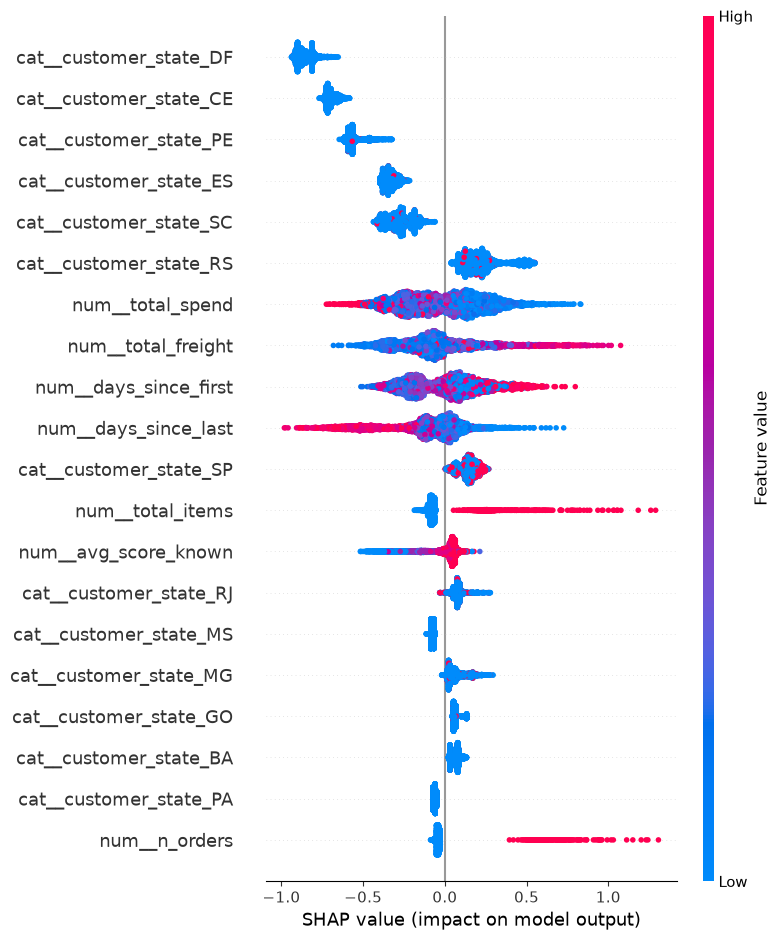

In [6]:
import shap
import matplotlib.pyplot as plt

pipe = variants["xgb_plain"]
prep_fit = pipe.named_steps["prep"]
clf = pipe.named_steps["clf"]
names = prep_fit.get_feature_names_out()

Xt = prep_fit.transform(X_test)
if hasattr(Xt, "toarray"):
    Xt = Xt.toarray()

rng = np.random.default_rng(42)
idx = rng.choice(len(Xt), size=5000, replace=False)
Xs = Xt[idx]

explainer = shap.TreeExplainer(clf)
sv = explainer.shap_values(Xs)

imp = pd.Series(np.abs(sv).mean(axis=0), index=names).sort_values(ascending=False)
print(imp.head(10).round(4))

shap.summary_plot(sv, Xs, feature_names=names, show=False)
plt.tight_layout()
plt.savefig("shap_summary.png", dpi=150)

In [7]:
def state_check(d):
    t = d.groupby("customer_state").agg(n=("cust", "size"), positives=("label", "sum"))
    t["rate_pct"] = (100 * t["positives"] / t["n"]).round(2)
    return t.loc[["DF", "CE", "PE", "ES", "SC", "RS", "SP"]]

print("train"); print(state_check(train))
print("test");  print(state_check(test))

train
                    n  positives  rate_pct
customer_state                            
DF               1179          1      0.08
CE                822          1      0.12
PE                967          2      0.21
ES               1209          5      0.41
SC               2210          8      0.36
RS               3283         27      0.82
SP              22440        189      0.84
test
                    n  positives  rate_pct
customer_state                            
DF               1609         10      0.62
CE               1090          3      0.28
PE               1288          6      0.47
ES               1608          7      0.44
SC               2917         17      0.58
RS               4356         21      0.48
SP              31343        201      0.64


In [8]:
prep_ns = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)),
                      ("sc", StandardScaler())]), num_cols),
])
Xtr_ns, Xte_ns = train[num_cols], test[num_cols]

variants_ns = {
    "logistic": Pipeline([("prep", clone(prep_ns)),
                          ("clf", LogisticRegression(max_iter=1000))]),
    "xgb_plain": ImbPipeline([("prep", clone(prep_ns)),
                              ("clf", XGBClassifier(**xgb_params))]),
    "xgb_weight": ImbPipeline([("prep", clone(prep_ns)),
                               ("clf", XGBClassifier(scale_pos_weight=pos_weight, **xgb_params))]),
    "xgb_under": ImbPipeline([("prep", clone(prep_ns)),
                              ("under", RandomUnderSampler(sampling_strategy=0.1, random_state=42)),
                              ("clf", XGBClassifier(**xgb_params))]),
}

rows = []
for name, model in variants_ns.items():
    cv_scores = cross_val_score(model, Xtr_ns, y_train, cv=cv, scoring="average_precision")
    model.fit(Xtr_ns, y_train)
    s = model.predict_proba(Xte_ns)[:, 1]
    rows.append({"model": name,
                 "cv_pr_auc": round(cv_scores.mean(), 4),
                 "test_pr_auc": round(average_precision_score(y_test, s), 4),
                 "test_recall_top1pct": round(recall_at_top(y_test, s), 3)})
pd.DataFrame(rows)

,model,cv_pr_auc,test_pr_auc,test_recall_top1pct
0,logistic,0.0259,0.0201,0.081
1,xgb_plain,0.0252,0.0161,0.067
2,xgb_weight,0.0171,0.0148,0.060
3,xgb_under,0.0197,0.0155,0.065


In [9]:
final = variants_ns["logistic"]
alt = variants_ns["xgb_plain"]
s_f = final.predict_proba(Xte_ns)[:, 1]
s_a = alt.predict_proba(Xte_ns)[:, 1]
y = y_test.to_numpy()

rng = np.random.default_rng(42)
out = []
for _ in range(1000):
    idx = rng.integers(0, len(y), len(y))
    yb = y[idx]
    if yb.sum() == 0:
        continue
    pf = average_precision_score(yb, s_f[idx])
    pa = average_precision_score(yb, s_a[idx])
    k = int(len(yb) * 0.01)
    top = np.argsort(s_f[idx])[::-1][:k]
    out.append((pf, pf / yb.mean(), yb[top].sum() / yb.sum(), pf - pa))
out = np.array(out)

for i, lab in enumerate(["logistic PR-AUC", "lift over no-skill",
                         "recall in top 1%", "difference vs xgb_plain"]):
    print(lab, np.round(np.percentile(out[:, i], [2.5, 97.5]), 4))

logistic PR-AUC [0.0131 0.0328]
lift over no-skill [2.2776 5.8356]
recall in top 1% [0.0535 0.1069]
difference vs xgb_plain [-0.0008  0.0092]


Background dataset has 56630 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=56630 when initializing the masker.


num__days_since_last                     0.6185
num__days_since_first                    0.4032
num__avg_score_known                     0.1397
num__total_spend                         0.0920
num__n_delivered_known                   0.0635
num__total_items                         0.0578
num__n_orders                            0.0414
num__missingindicator_avg_score_known    0.0190
num__total_freight                       0.0136
num__n_late_known                        0.0057
dtype: float64


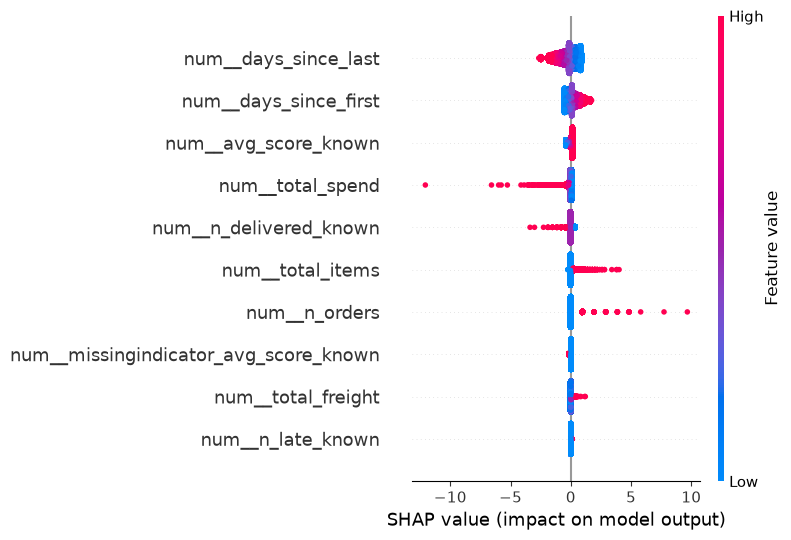

In [10]:
import shap
import matplotlib.pyplot as plt

final = variants_ns["logistic"]
prep_f = final.named_steps["prep"]
clf_f = final.named_steps["clf"]
names_f = prep_f.get_feature_names_out()

Xtr_t = prep_f.transform(Xtr_ns)
Xte_t = prep_f.transform(Xte_ns)

explainer = shap.LinearExplainer(clf_f, Xtr_t)
sv_f = explainer.shap_values(Xte_t)

imp_f = pd.Series(np.abs(sv_f).mean(axis=0), index=names_f).sort_values(ascending=False)
print(imp_f.round(4))

shap.summary_plot(sv_f, Xte_t, feature_names=names_f, show=False)
plt.tight_layout()
plt.savefig("shap_logistic.png", dpi=150)

In [11]:
from statsmodels.stats.proportion import proportion_confint

def late_vs_ontime(d, name):
    k = d[d["n_delivered_known"] > 0].copy()
    k["had_late"] = k["n_late_known"] > 0
    g = k.groupby("had_late")["label"].agg(n="size", repeaters="sum")
    g["rate_pct"] = (100 * g["repeaters"] / g["n"]).round(2)
    lo, hi = proportion_confint(g["repeaters"], g["n"], method="wilson")
    g["ci_low_pct"] = (100 * lo).round(2)
    g["ci_high_pct"] = (100 * hi).round(2)
    print(name)
    print(g)

late_vs_ontime(train, "train")
late_vs_ontime(test, "test")

train
              n  repeaters  rate_pct  ci_low_pct  ci_high_pct
had_late                                                     
False     49313        335      0.68        0.61         0.76
True       2700         16      0.59        0.37         0.96
test
              n  repeaters  rate_pct  ci_low_pct  ci_high_pct
had_late                                                     
False     67711        370      0.55        0.49         0.60
True       5335         27      0.51        0.35         0.74
